# Transformer

## RNN 한계
- 기존 모델 Seq2Seq은 Context Vector의 크기가 고정되어 있어 입력이 5단어든 50단어든 같은 크기의 벡터에 모든 정보를 담아야 함. 디코더는 Context Vector 하나만을 이용해 출력 문장을 생성하기 때문에 문장이 길어질수록 정보손실의 문제가 발생

### Attention의 등장
- 이러한 한계를 해결하기 위해 등장 한 것이 Attention. Attention은 디코더가 단어를 생성할 때마다 입력 문장 전체를 다시 보고, 현재 단어와 관련 있는 부분에 집중하여 출력 단어마다 새로운 Context Vector를 만듦.

#### Attention의 정의
_현재 시점에서 가장 중요한 부분에 더 높은 가중치를 부여하는 기술_ <br>
_출력 단어를 생성할 때 입력 문장 속 단어들 중 어떤 단어에 더 집중할지의 정도를 결정_

#### Attention 과정
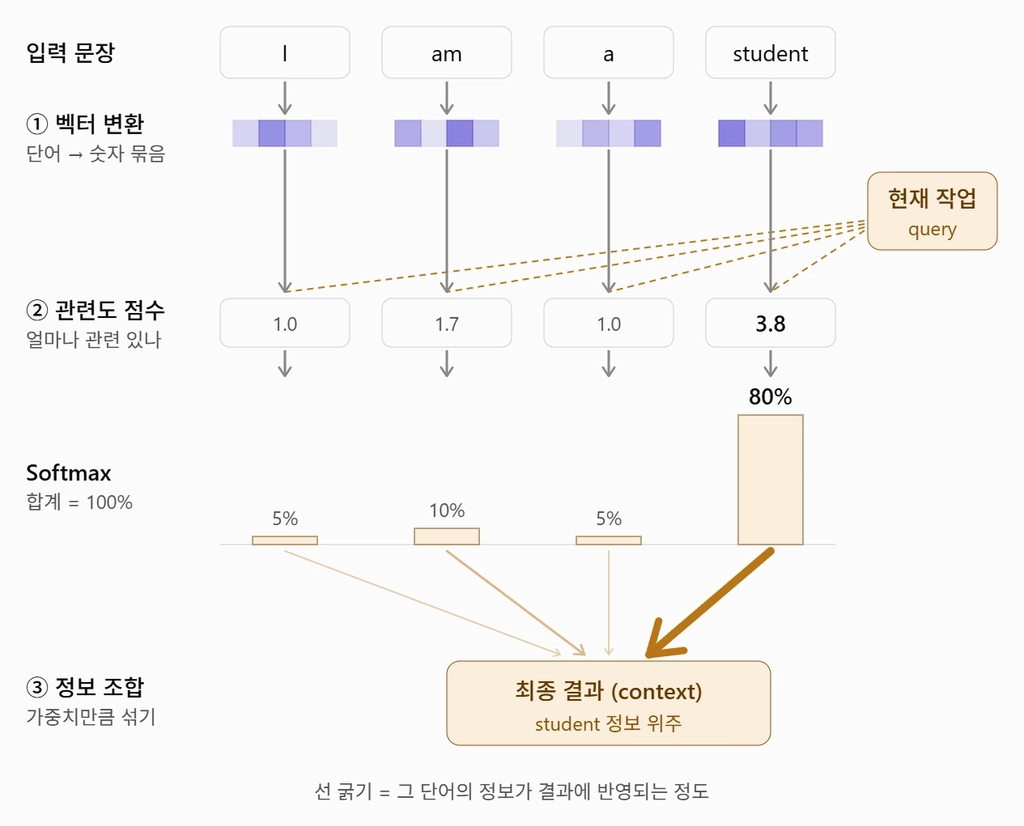
<br>

1. 입력을 벡터 형태로 변환 :
    
    입력 단어를 컴퓨터가 읽을 수 있도록 숫자로 이루어진 벡터로 변환
    
2. 단어별 중요도 계산 :
    - **관련도 점수** - 현재 작업과 각 단어 사이의 관계가 얼마나 관련이 높고 유사한지 점수를 매김.
    - **Softmax** - 관련도 점수를 0~1 사이의 확률 값으로 변환. 모든 단어의 중요도 합이 1인 비율로 바꿔주는 함수이고 이 Softmax를 거친 비율을 Attention Weight(어텐션 가중치)라고 함.
    
    → 그림을 보면, student는 3.8점의 관련도 점수를 받았고, Softmax를 거쳐 80%의 가중치가 됨. 즉 모델이 ***“student 단어에 80%를 집중하겠다”***고 판단한 것.
3. 중요도에 따른 입력 정보 조합 :
    
    어텐션 가중치(비율)만큼 각 단어의 hidden state 정보를 섞어 Context Vector를 만듦. 이 과정에서 **가장 비율이 높은 단어 정보**를 위주로 반영하여 다음 결과를 구성하게 됨.
### Attention is All You Need
_Transformer 구조를 처음 발표한 논문 (Self-Attention 방식)_
<br>
1. 논문 배경 : RNN과 RNN 기반 모델들의 한계
    
2. Transformer의 등장
    
3. 논문에서 가장 중요한 발견
    
    ***“Recurrence(순환)와 Convolution(합성곱)은 필수가 아니다”***
    
    - 그 동안 순서가 있는 데이터를 다루려면 RNN처럼 순서대로 처리해야 한다고 여겨졌지만, 이 논문은 Attention만으로 더 좋은 성능을 낼 수 있고, 순차 구조를 없앤 덕분에 **병렬화를 통한** **빠른 학습 속도가 가능**해짐.
4. 파급효과
    - LLM의 탄생 : Transformer의 디코더를 쌓은 GPT, 인코더를 쌓은 BERT가 등장하며 오늘날 대형 언어 모델의 기반이 됨.
    - NLP 평정 : 번역, 요약, 질의응답 등 자연어 처리 대부분의 표준 구조로 자리잡음.
    - 타 분야로의 확장 : 이미지, 음성 등으로 확장. 논문 결론에서도 저자들은 이미지·오디오**·**비디오의 확장을 향후 계획으로 언급.

#### Transformer 정의

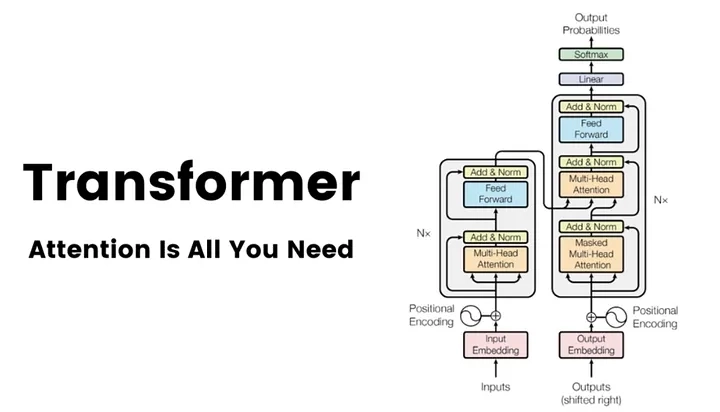
<br>

_RNN처럼 단어를 순서대로 처리하지 않고 Attention만으로 문장 전체의 의미와 구조를 파악하여 한 번에 처리하는 인코더-디코더 모델_

| **구분** | **Seq2Seq + Attention** | **Transformer** |
| --- | --- | --- |
| 인코더, 디코더의 내부 | LSTM (순차 처리) | Self-Attention |
| 어텐션의 역할 | RNN을 돕는 보조 역할 | 모델 그 자체 |
| 어텐션 사용 위치 | 디코더 → 인코더 1곳 | 인코더 내부, 디코더 내부, 인코더-디코더 사이 3곳 |
| 단어 순서 정보 | RNN이 순서대로 읽으며 반영 | Positional Encoding으로 따로 추가 |
| 병렬 처리 | 불가 | 가능 |

#### Transformer의 핵심 기술

- Self-Attention : 문장 안의 단어들이 서로를 참고해 얼마나 중요한 관계를 맺고있는지 한 번에 문맥을 파악하는 기술
- Multi-Head Attention : Attention을 여러 갈래로 나눠 다양한 관점에서 관계를 파악함
- Positional Encoding : 각 단어의 위치를 벡터로 만들어 단어 벡터에 더함으로써, 사라진 순서 정보를 보완

## Self_Attention

### Query, Key, Value
_Attention은 Query를 Key들과 비교해 관련도를 구하고 그 비율만큼 Value를 섞어 결과를 만드는 계산_
<br>

- **Q : Query(쿼리)**
    
    현재 처리 중인 단어가 다른 단어들에게 “지금 나한테 필요한 정보가 뭐지?”라고 묻는 벡터
    
    - 예시
        
        도서관 예시: “’학생’에 대해 알고 싶어” 라는 궁금증

- **K : Key(키)**
    
    각 단어가 “나는 이런 정보를 가지고 있어” 라고 보이는 벡터. 즉, 키는 검색 대상이 되는 모든 정보의 ‘이름표’
    
    Query와 비교하여 관련도 점수를 결정
    
    - 예시
        
        ‘학교 생활’, ‘교육학 개론’, ‘요리 레시피’, ‘주식 투자’ 제목표 → ‘학생’과 비교하여, 60%, 35%, 3%, 2%
        
    
- **V : Value(밸류)**
    
    각 단어가 실제로 전달하는 정보 벡터. 관련도 비율만큼 모든 Value를 섞어 최종 결과를 만듦
    
    - 예시
        
        학교 생활 책 내용 60% + 교육학개론 35% + 요리 레시피 3% + 주식투자 2% → 최종 답변
### Cross-Attention vs. Self-Attention

#### 기존 Attention in Seq2Seq (Cross-Attention)
- Query와 Key-Value쌍이 서로 다른 시퀀스에서 출력
- Cross-Attention은 하나의 시퀀스가 독립된 다른 시퀀스를 참고하여 정보를 만들어내는 매커니즘

##### 핵심 과정
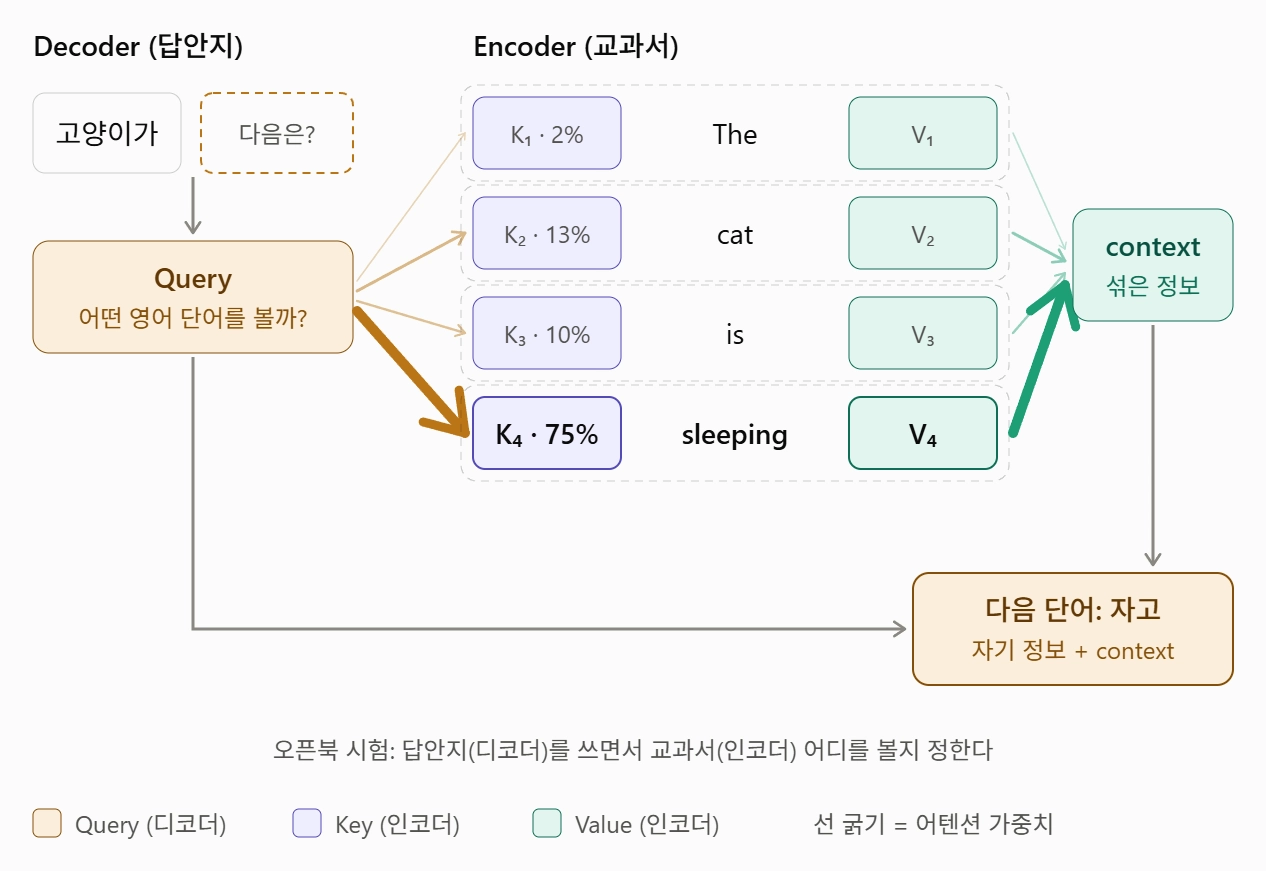 <br>

1. Query 만들기
    
    디코더가 지금까지 만든 “고양이가”를 바탕으로 현재 상태를 Query로 만듦 → “다음 단어를 위해 어떤 영어 단어를 봐야 할까?”
    
2. Key, Value 불러오기
    
    인코더가 원문의 각 단어 (The, cat, is, sleeping)에 대해 만들어 둔 벡터를 Key와 Value로 사용
    
3. 유사도 계산 (Attention Score)
    
    관련도 계산 :
    
    $$
    	Q\ \cdot \ K_i \ \ (내적)
    $$
    
    Query와 각 Key의 관련도를 계산하고 Softmax로 확률의 값 비율로 변환 → The 2%, cat 13%, is 10%, **sleeping 75%**
    
4. Weighted Sum
    
    비율만큼 Value를 섞어 Context Vector 생성 → 디코더 자기 정보 + Context Vector로 다음 단어 “자고” 출력

#### Self-Attention
Query와 Key - Value쌍이 같은 시퀀스에서 출력
문장이 스스로에게 “우리끼리 누가 누구와 관련이 있지?”라고 묻는 구조예요. RNN없이도 문장 내부의 관계와 문맥을 직접 파악할 수 있음.

#### 핵심 과정
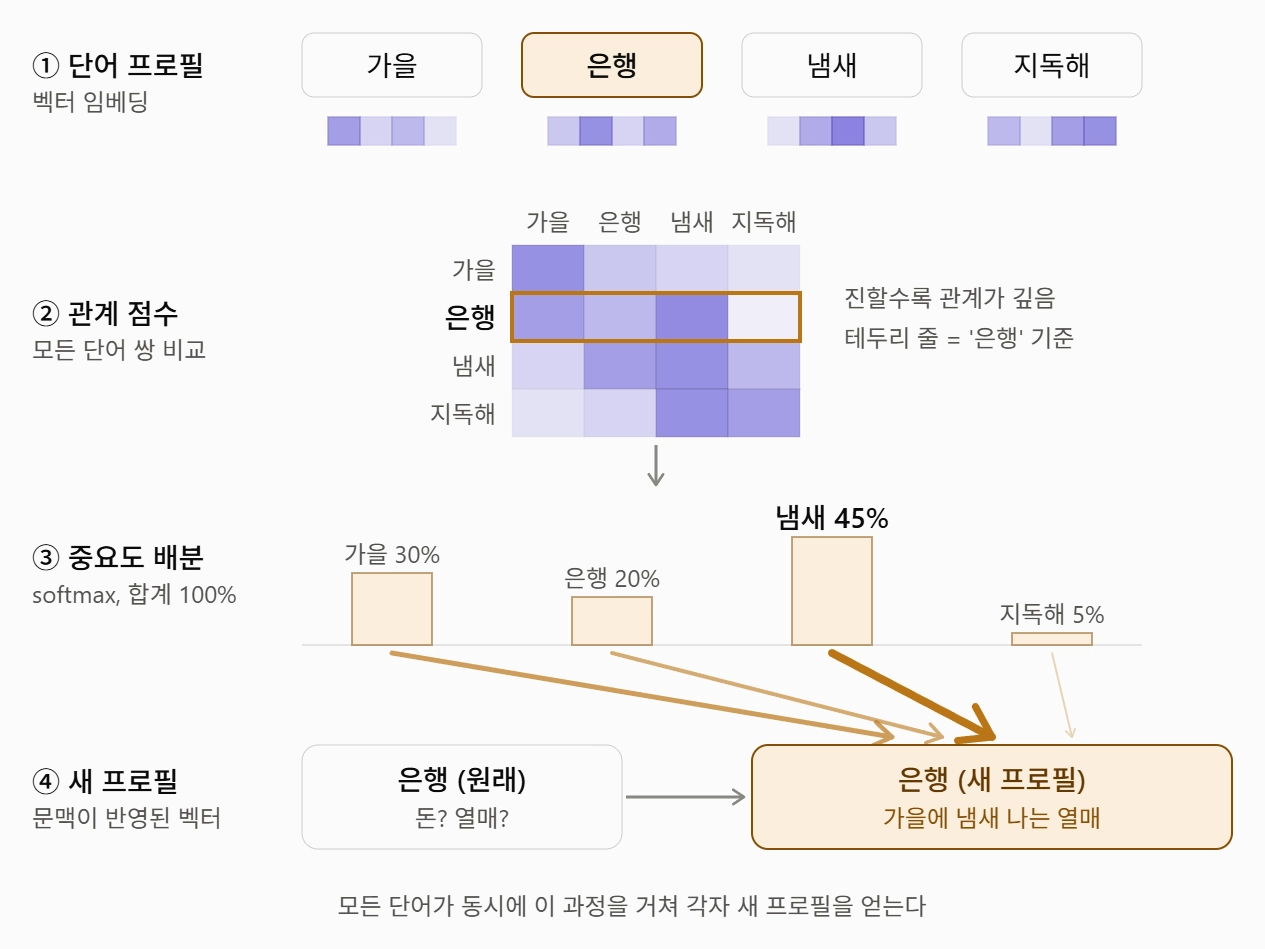 <br>

1. 벡터 임베딩
    
    각 단어를 컴퓨터가 읽을 수 있도록 벡터로 변환하고 같은 벡터에서 Q, K, V를 만듦
    
2. 내적 및 관련도 점수
    
    ‘은행’의 Query와 모든 단어의 Key를 비교해 관계 점수 계산 (가로줄 = 질문하는 단어, 세로줄 = 참고 대상)
    
3. 중요도 배분 (Softmax & 어텐션 가중치)
    
    가을 30%, 은행 20%, **냄새 45%**, 지독해 5%로 비율 변환 및 특정 단어를 이해에 대한 각각의 %로 중요도 판단
    
4. 새로운 벡터 생성
    
    비율만큼 Value를 섞어 ‘은행’이 “돈? 열매?”에서 **“가을에 냄새 나는 열매”**라는 의미를 담은 새 벡터가 생성

#### 비교 표
| 구분 | Cross-Attention | Self-Attention |
| --- | --- | --- |
| point | 번역 중인 문장이 원문을 참고 | 문장이 스스로 내부 관계를 파악 |
| 작동 방식 | 디코더의 Query로 인코더의 Key, Value를 조회 | 같은 문장에서 만든 Q, K, V로 모든 단어끼리 비교 |
| 참조 대상 | 서로 다른 시퀀스 (디코더 → 인코더) | 서로 같은 시퀀스 (문장 내부) |
| 주요 목적 | 고정 Context Vector의 병목 해결 | 문맥이 반영된 단어 표현 생성 |
| 결과 벡터 | Context Vector | 문맥이 반영된 새 표현 |
| 기반 아키텍처 | RNN | Transformer |
| 병렬처리 | RNN 기반일 때 불가능 | 가능 |


### Scaled Dot-Product Attention
#### Dot-Product Attention
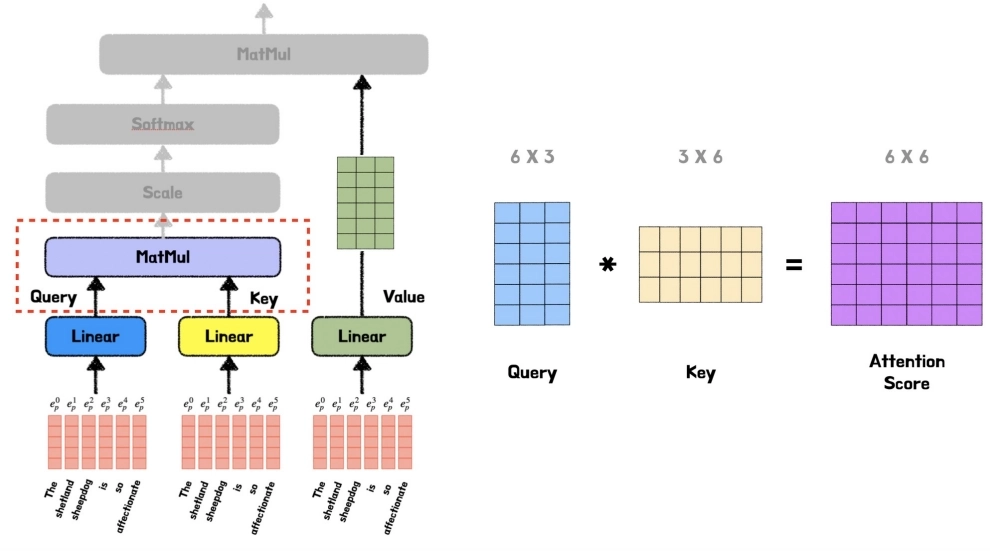 <br>

- **Attention Score를 계산하는 가장 기본적인 방법 중 하나!**
    - Query와 Key 벡터를 **내적**하여 관련도 점수를 구하는 방식
    - 내적 :
        
        두 벡터의 같은 위치 성분끼리 곱해 모두 더한 값. 방향이 비슷할수록 큰 값 → “얼마나 닮았나”를 숫자로 표현
        
        $$
        Q \cdot K = \sum_{i=1}^{d_k} Q_iK_i
        $$
##### Dot-Product Attention의 기본적인 과정

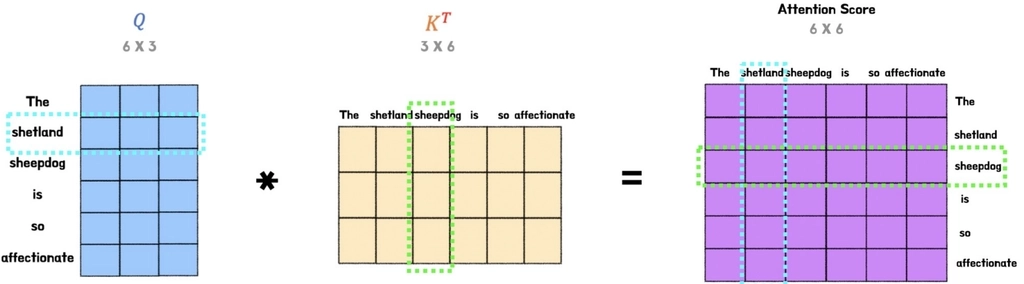 <br>

1. Attention Score 계산
    - Query (6x3)와 전치한 Key (3x6)를 곱함
    - 결과 (6x6) : 모든 단어 x 모든 단어의 관련도 점수표
    - 행렬 곱셈 한 번으로 36개 점수를 **동시에** 계산 → 병렬 처리가 실제로 구현되는 지점

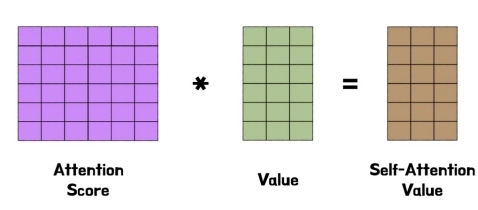 <br>

2. 계산된 값에 Softmax 적용 → Attention Weight 산출
    
    
    
    - 점수표의 각 가로줄을 합이 1인 비율로 전환
    - “이 단어는 다른 단어들을 몇 %씩 참고하는가”를 나타냄

3. 최종 결과값 계산
    - Attention Weight(6x6) x Value → 각 단어가 다른 단어 정보를 비율만큼 섞은 새 벡터 6개 (행 기준)

#### Scaled Dot-Product Attention
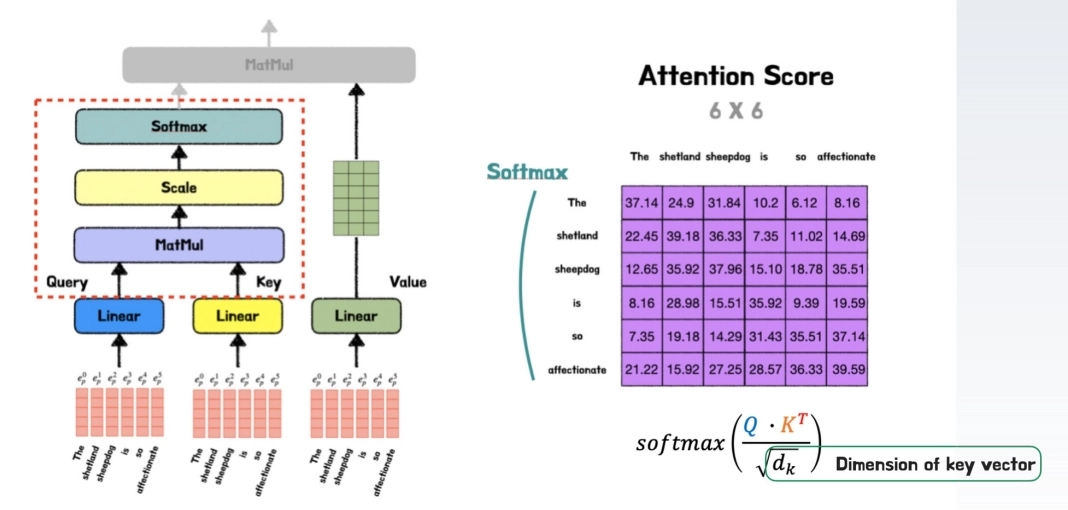<br>
_Transformer의 Attention 계산 공식 그 자체_

- 과정
    1. Query와 모든 Key를 내적 → Attention Score
    2. Attention Score를 **$\sqrt{d_k}$**로 나누는 스케일링 과정 진행
    3. Softmax 적용 → Attention Weight 산출
    4. Attention Weight x Value → 최종 결과

- **$\sqrt{d_k}$**로 나누면 분산이 다시 1 근처로 돌아와, 차원의 크기와 상관없이 점수가 안정적인 범위에 머물 수 있게 됨.

> **Scaled Dot-Product Attention 계산의 결과로 얻어지는 벡터**

- Cross-Attention : Context Vector
    
    현재 생성 중인 단어에 필요한 원문 정보를 비율만큼 모은 벡터
    
- Self-Attention
    
    문장 내 다른 단어들과의 관계가 반영되어 **의미가 업데이트**된 단어 벡터


### Single-Head Attention VS. Multi-Head Attention
**Head: Attention 계산을 한 번 하는 독립된 단위** <br>

#### Single-Head Attention
- 헤드가 1개
- 가중치 행렬 세트 하나로, 512차원 벡터를 그대로 한번 Attention 진행. 그 결과 단어마다 가중치 분포가 딱 하나 나옴.
- 방식
1. 각 단어의 512차원 벡터에 가중치 행렬 $W^Q, W^K, W^V$를 한 세트만 곱해서 Q, K, V를 만듦.
2.  Q, K로 점수를 매기고 $\sqrt{d}$로 나눈 뒤 Softmax를 적용하여 가중치 분포 하나를 얻음. (이 분포의 합은 1(100%))
3. 이 가중치로 V를 섞어서 새 512차원 벡터 하나를 출력.

- 한계: 집중력 100%를 혼자 나눠 써야 함.
Softmax를 거친 가중치는 합이 항상 1(100%).
헤드가 하나뿐이면 이 100%를 여러 관계에 골고루 나눠 줄 수밖에 없고, 결과는 여러 정보가 섞여 흐릿해진 벡터 하나가 됨.

- 예시
“Tom gave Mary a book yesterday”

| 단어 | Tom | Mary | a | book | yesterday |
| --- | --- | --- | --- | --- | --- |
| “gave”의 가중치 | 0.25 | 0.25 | 0.02 | 0.25 | 0.23 |

> 네 단어가 다 중요하여 비슷하게 나눠 줄 수밖에 없어 준 사람의 의미가 흐려짐.

#### Multi-Head Attention
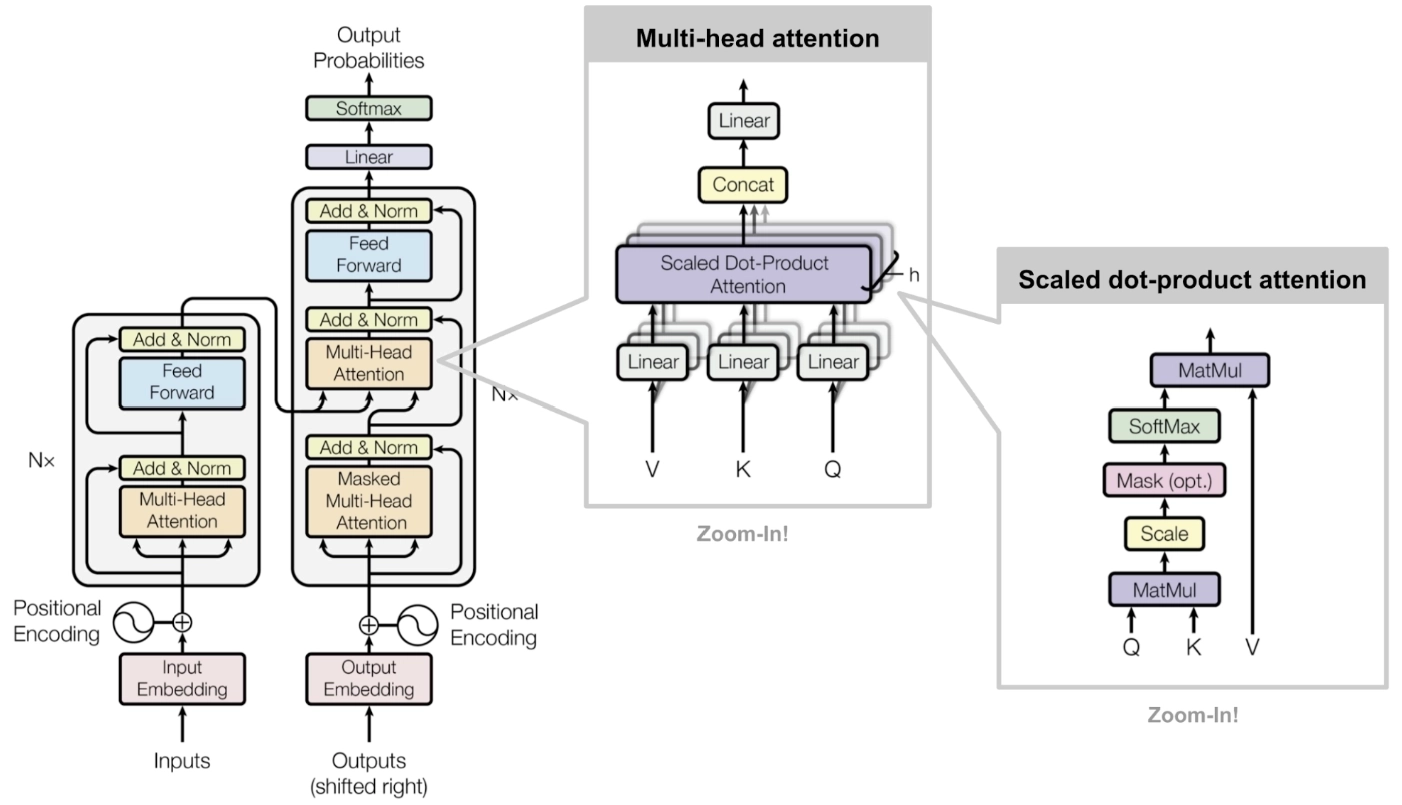 <br>
_Attention을 작게 쪼개서 여러 번 동시에 하는 방식_ <br>
- 방식
1. 512차원 벡터에 **헤드마다 다른** $W^Q, W^K, W^V$를 곱해서 64차원 Q, K, V를 **8세트** 만듭니다.
2. 8개 헤드가 서로 간섭하지 않고 각자 Attention을 계산합니다. (가중치 분포가 8개 나오게 됨)
3.  8개의 64차원 결과를 이어 붙여(Concat) 다시 512차원으로 만듭니다.
4.  마지막으로 $W^O$를 곱해서 8개의 관점을 하나로 섞습니다.

- 예시
“Tom gave Mary a book yesterday”

> Multi-Head Attention: 헤드마다 각자 100%를 쓴다.

| 헤드 | 주로 보는 단어 | 가중치 | 담당하는 질문 |
| --- | --- | --- | --- |
| 헤드 1 | Tom | 0.90 | Who? |
| 헤드 2 | Mary | 0.90 | To whom? |
| 헤드 3 | book | 0.90 | What? |
| 헤드 4 | yesterday | 0.90 | When? |

### Multi-Head Attention 작동 방식

- “I love you”에서 love 한 단어가 Multi-Head Attention을 통과하는 과정을 통해 알아보자.

- 작동 단계 예시
| 단계 | 하는 일 | 크기 변화 | 기자 비유 |
| --- | --- | --- | --- |
| ① 분할(Projection) | 헤드마다 다른 W를 곱해 작은 Q·K·V를 만듦 | 512 → 64 × 8세트 | 기자 8명에게 취재 수첩 배분 |
| ② 병렬 어텐션 계산 (Attention) | 8개 헤드가 동시에, 서로 간섭 없이 Attention 계산 | 64 × 8개 결과 | 각자 자기 분야 취재 |
| ③ 결합 (Concat) | 8개 결과를 한 줄로 연결 | 64 × 8 → 512 | 기사 8편을 한 묶음으로 |
| ④ 최종 투영 (Final Projection) | $W^O$를 곱해 8개 관점을 하나로 융합 | 512 → 512 | 편집장이 한 기사로 다듬기 |

<aside>

> **① 분할 (Projection) - 8개의 관점 만들기**

love라는 단어를 나타내는 512차원 벡터 하나에 헤드마다 다른 가중치 행렬을 곱해서, 64차원짜리 Q·K·V를 8세트 생성.

| **헤드** | **Query** | **Key** | Value |
| --- | --- | --- | --- |
| 헤드 1 | love × $W_1^Q$ → 64차원 | love × $W_1^K$ → 64차원 | love × $W_1^V$ → 64차원 |
| 헤드 2 | love × $W_2^Q$ → 64차원 | love × $W_2^K$ → 64차원 | love × $W_2^V$ → 64차원 |
| … | … | … | … |
| 헤드 8 | love × $W_8^Q$ → 64차원 | love × $W_8^K$ → 64차원 | love × $W_8^V$ → 64차원 |

문장의 다른 단어 (I, you)도 똑같이 8세트씩 생성됨.

> **② 병렬 어텐션 계산 (Attention) - 각 헤드별 각자 분석**


8개 헤드가 서로 간섭하지 않고 동시에 Scaled Dot-Product Attention을 계산.

- 헤드 1 안에서의 과정?

<aside>

1. **점수 매기기 (Score):** 
    
    love의 $Q_1$ 을 I, love, you의 $K_1$과 각각 내적하여 관련도 점수 3개를 계산
    
2. **크기 조절 (Scale):** 
    
    계산된 점수를 각 헤드 차원의 제곱근 ($\sqrt{64} = 8$)으로 나눠줌. (점수가 너무 커져 한 단어가 독차지하는 것을 막음)
    
3. **가중치 변환 (Softmax):** 
    
    조절된 점수들에 Softmax를 적용하여 합이 1인 어텐션 가중치를 만듦.
    
    → 예: I 0.2, love 0.7, you 0.1
    
4. **섞기 (Weighted Sum):** 
    
    이 가중치대로 I, love, you의 $V_1$에 곱해서 모두 더하면 **헤드 1의 결과 (64차원)**
    
</aside>

헤드 2~8도 각자의 Q·K·V로 같은 계산을 **동시에, 독립적으로** 진행 → 64차원 결과 8개

> **③ 이어 붙이기 (Concat)**
> 

8개의 64차원 결과를 순서대로 한 줄로 이어 붙여 512차원(8×64) 벡터 생성

> **④ 섞기 (Final Projection)**
> 

이어 붙인 벡터는 아직 각 헤드의 분석 결과를 단순히 나열한 것. 따라서 이 벡터에 또 하나의 행렬 $W^O$(512×512)를 곱해, 8개 관점을 **하나의 의미로 융합** 

⇒ 모든 단계가 끝나면 ‘love’라는 단어에 대한 **Multi-Head Attention 레이어의 최종 출력 벡터**를 얻게 됨.

</aside>

## Transformer 전체 아키텍처
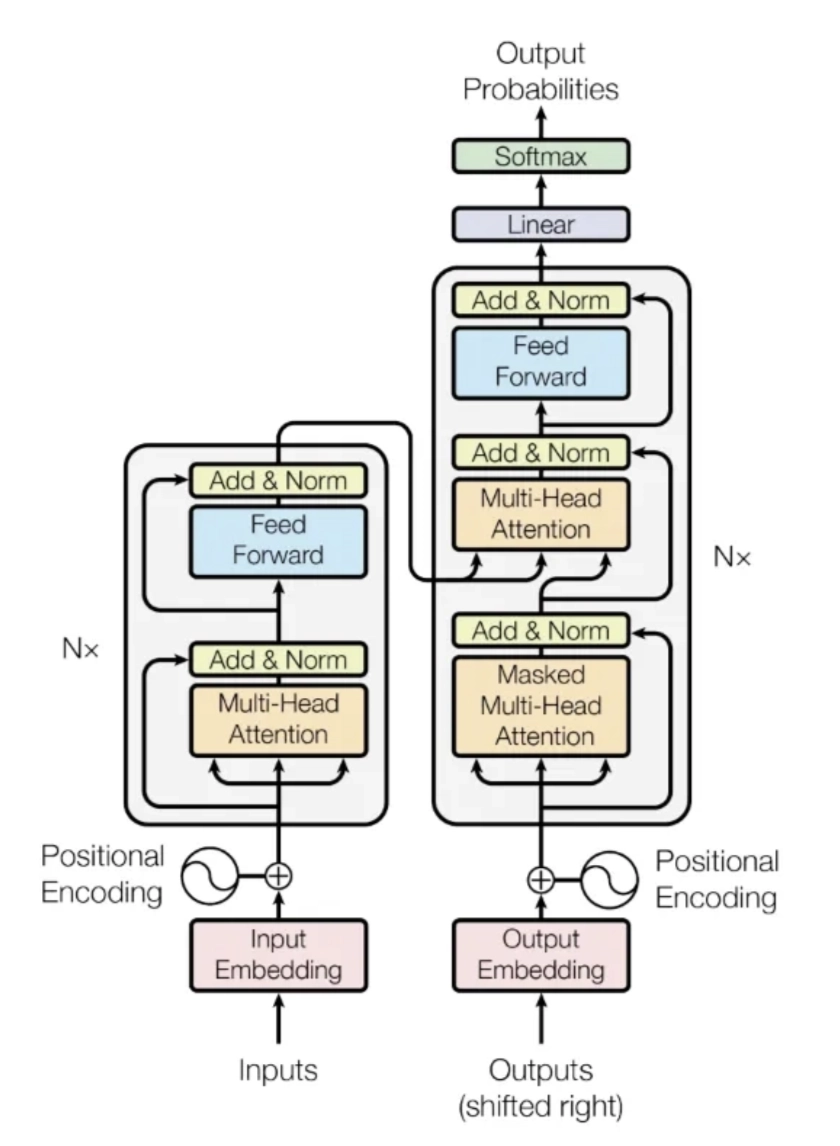 <br>

### 트랜스포머의 전처리 단계
**텍스트 입력(Inputs) → 텍스트 토큰화 (Tokenization) → 토큰 임베딩 (Embedding) → Positional Encoding**<br>
<br>

1. 토큰화 (Tokenization): 문장을 조각내기
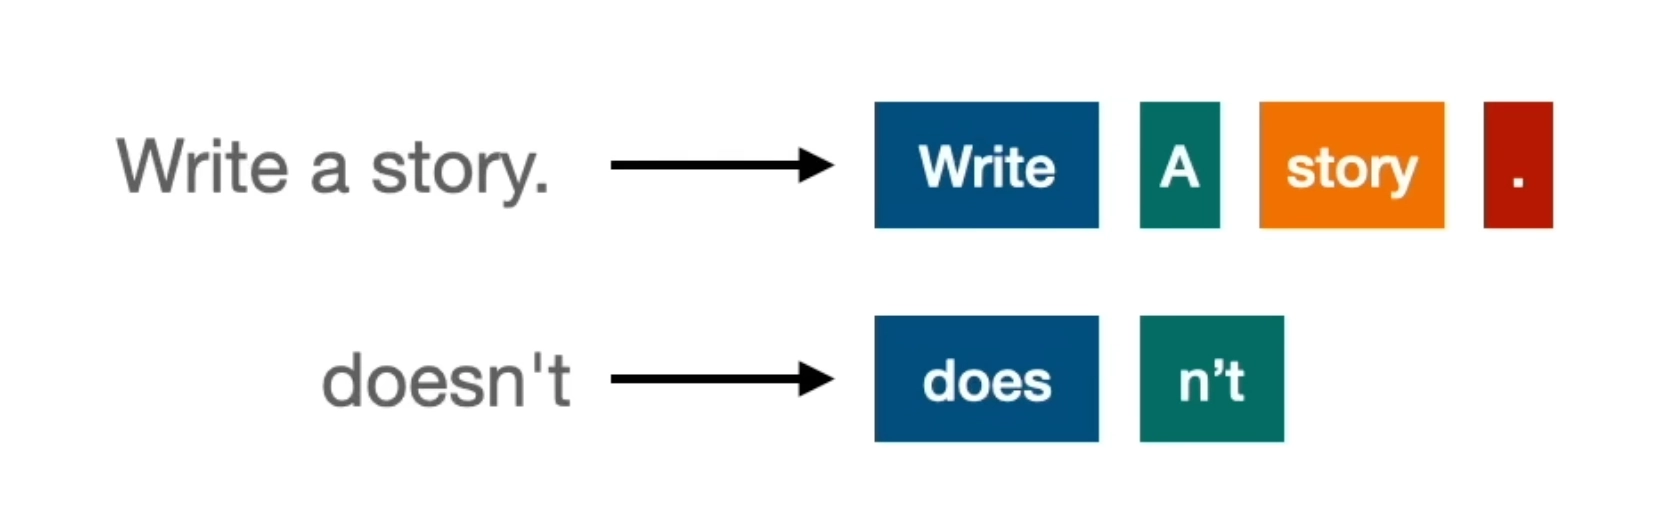 <br>

- 보통 단어 하나 = 토큰 하나: `Give`, `me`, `an` ,`apple`
- 문장 부호도 토큰: `.`, `!`
- 길거나 드문 단어는 여러 조각: `didn't` → `did` + `n't`

_토큰화 과정: 문장을 모델이 다루는 기본 단위(토큰) 로 자르는 것_ <br>

2. 임베딩 (Embedding): 단어에 좌표 주기
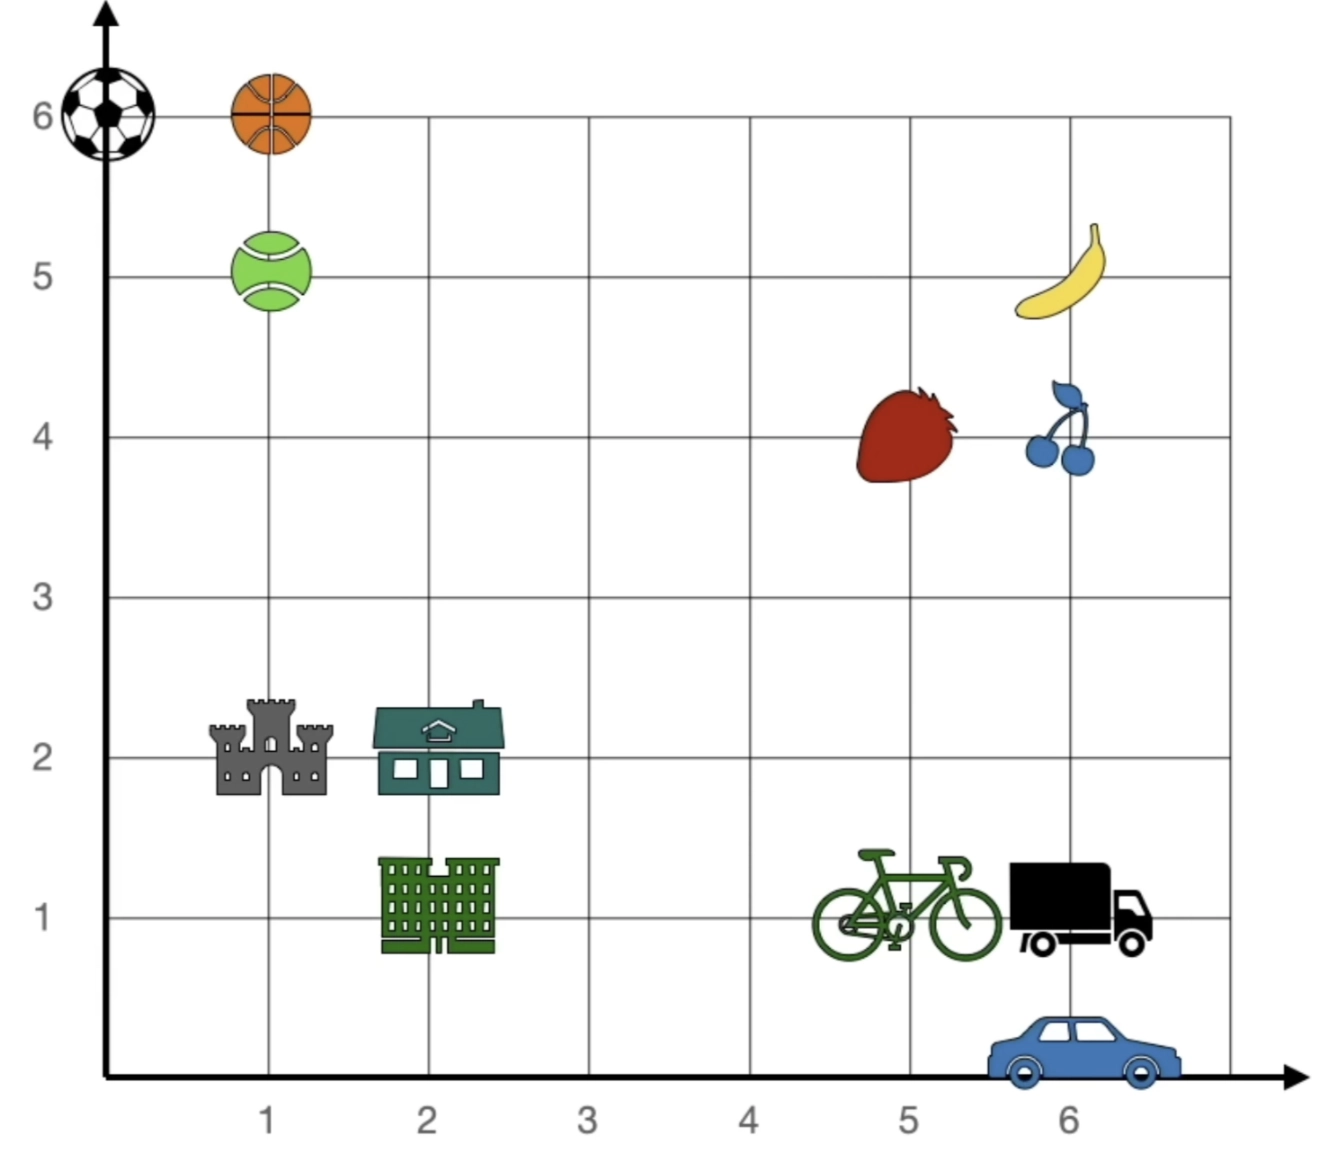 <br>
예시: 지도 위의 동네 딸기(5, 4)와 체리(6, 6)은 ‘과일 동네’ 이웃에 살고, 성 (2, 1)은 멀리 ‘건물 동네’에 산다.
 → 실제로는 512차원 지도이기 때문에 색깔, 먹을 수 있는지, 크기 등 수백 가지 특징을 동시에 담을 수 있음.

_임베딩 과정은 각 토큰을 숫자(벡터)로 바꾸는 것_ <br>

- 핵심 원리: 뜻이 비슷한 단어는 가까운 좌표에 놓인다

3. Positional Encoding: 순서 번호표 붙이기
_단어들의 순서 정보를 임베딩 벡터에 추가하는 단계_
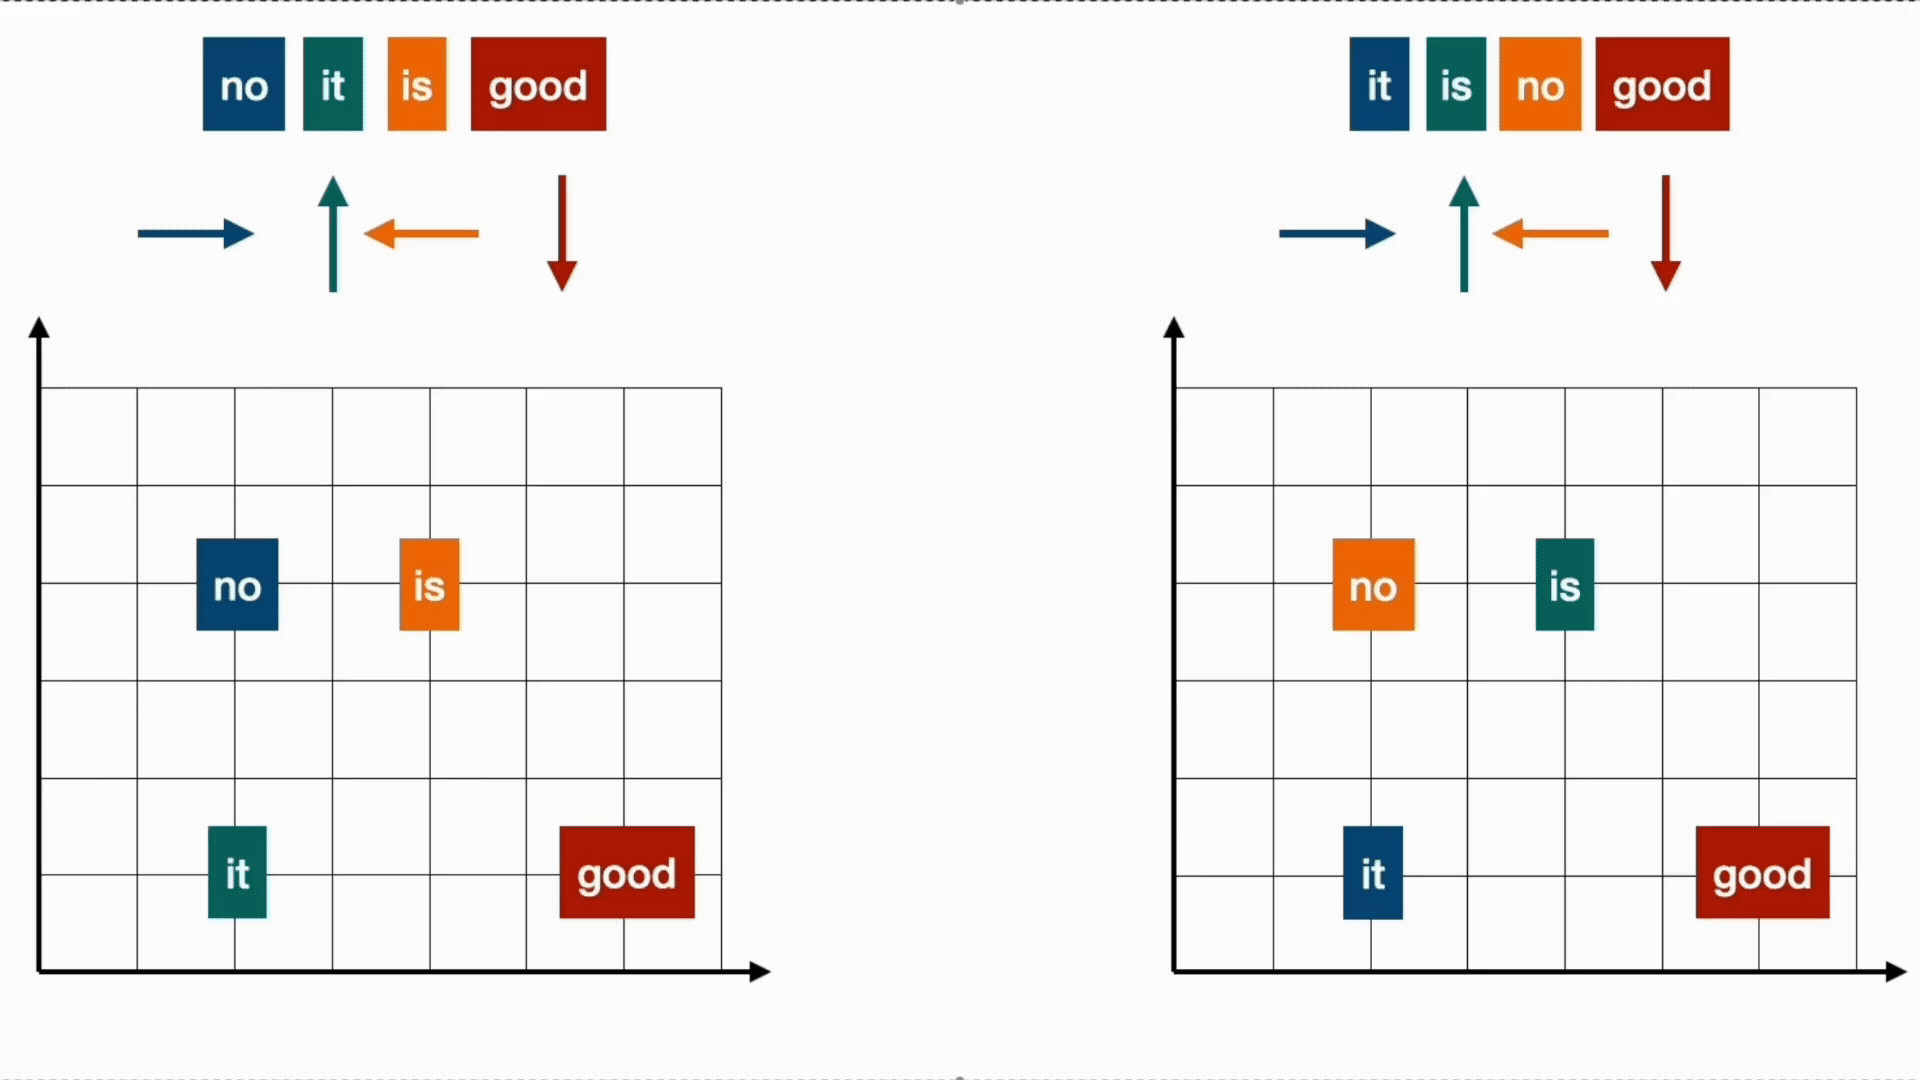 <br>
각 위치마다 **정해진 512차원 '위치 벡터'**를 만들어 임베딩에 **더합니다.** (이어 붙이는 게 아니라 숫자끼리 더함).

- 이때, 1번째 자리에는 항상 벡터 A, 2번째 자리에는 항상 벡터 B…처럼 **문장이 달라도 규칙은 같아야** 모델이 순서를 배울 수 있습니다.
- 같은 단어라도 자리가 다르면 최종 벡터가 달라집니다.

### Encoder와 Decoder

#### Encoder: 원문을 깊이 이해하는 분석팀
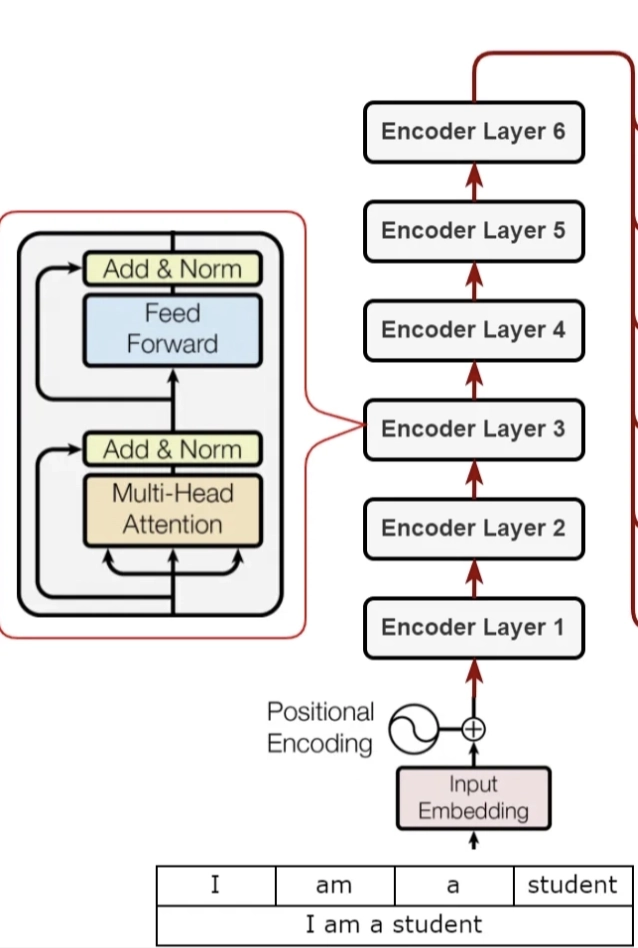 <br>

1. Multi-Head Self-Attention:
    
    원문 단어끼리 서로를 보며 문맥 파악
    
2. Feed-Forward Network: 
    
    단어 하나하나를 따로 더 깊이 가공

##### Add & Norm: 모든 부품에 붙는 안전장치
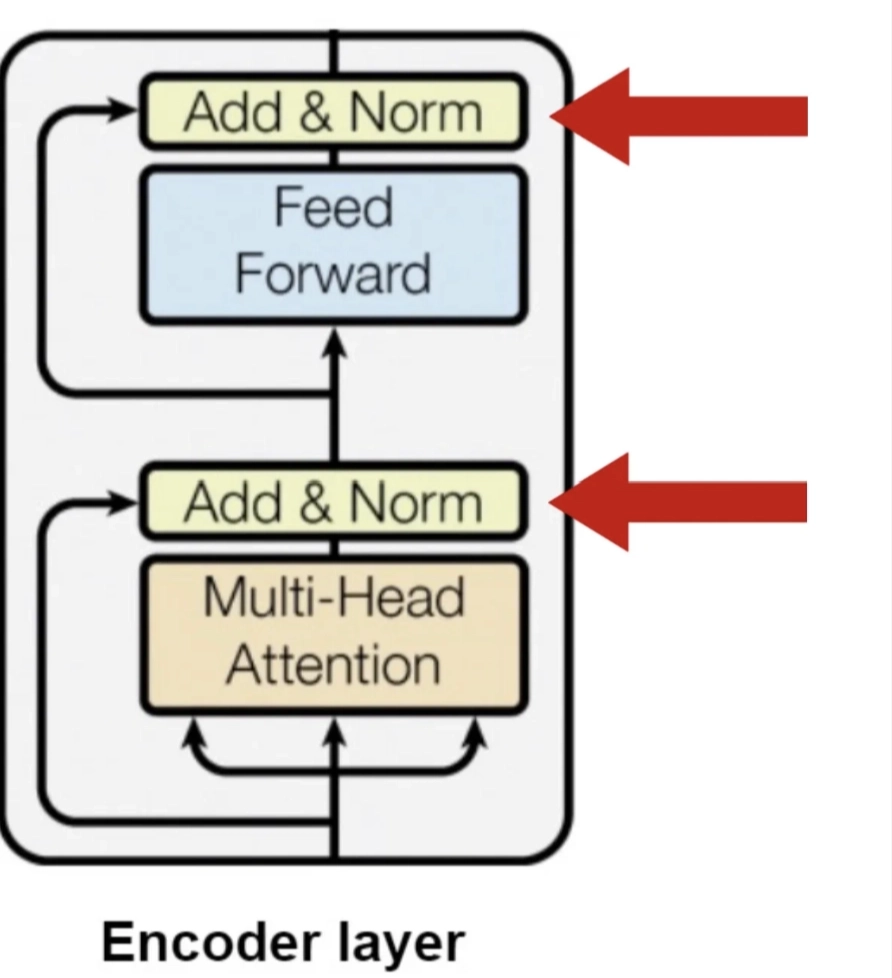 <br>
- **Add = Residual Connection (잔차 연결)**
    
    부품을 통과한 결과에 **원래 입력을 그대로 더해** 줍니다. 앞선 CNN 모델 중에 ResNet이라는 모델에서 나온 아이디어
    
- **Norm = Layer Normalization (층 정규화)**
    
    한 단어 벡터안의 512개 숫자를 평균 0, 분산 1 근처로 맞춤.

#### Decoder: 번역문을 한 단어씩 쓰는 작성팀
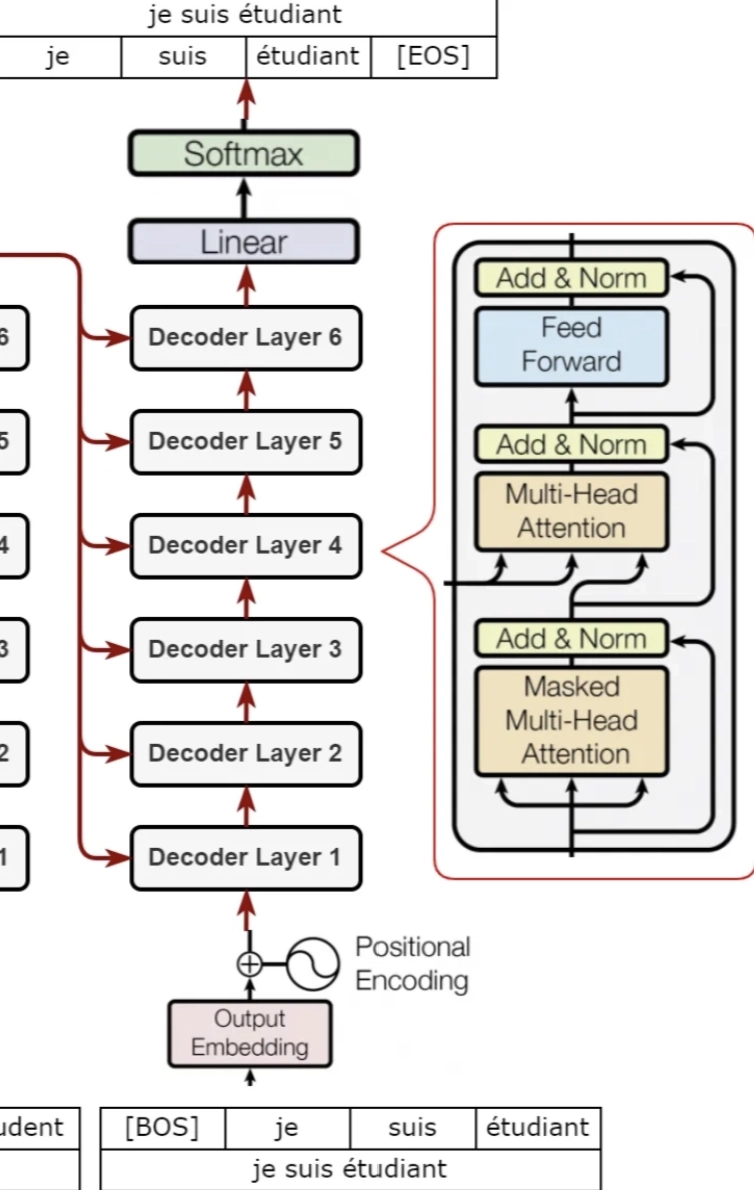 <br>

1. **Masked Multi-Head Self-Attention:** 
    
    지금까지 쓴 번역 단어끼리 관계 파악 (미래 단어는 가림)
    
2. **Encoder-Decoder Attention (Cross-Attention):** 
    
    원문 분석 자료(Encoder 출력)에서 필요한 부분 찾기
    
3. **Feed-Forward Network:**
    
    Encoder와 동일

##### Masked Multi-Head Attention
- Masked Multi-Head Attention이란?
    
    Decoder의 Self-Attention에서 **미래 시점의 단어 정보를 가려**(Softmax 후 0) **자기보다 앞의 단어만 보게 하는 메커니즘**
    
- 역할
    
    학습 때는 정답 문장 전체를 한 번에 넣어 병렬로 학습하는데, 마스크가 없으면 답을 미리 보고 맞히는 “컨닝”이 됨.
    
    시험 볼 때 뒤 문제의 답안을 종이로 가려두는 것과 같은 역할

##### Encoder-Decoder Attention (Cross-Attention)
- Encoder-Decoder Attention이란?
    
    출력 문장 (Decoder)과 입력 문장 (Encoder)을 연결하는 과정
    
- Q·K·V의 출처:
    - **Q = 직전 Decoder 서브레이어의 출력**
    - **K·V = Encoder 마지막 층의 출력** (6개 디코더 레이어가 모두 같은 Encoder 출력을 씀).